Train: 11314 Test: 7532
           Model  Accuracy  Precision  Recall     F1
0  MultinomialNB     0.651      0.634   0.637  0.618
1    BernoulliNB     0.485      0.617   0.469  0.468


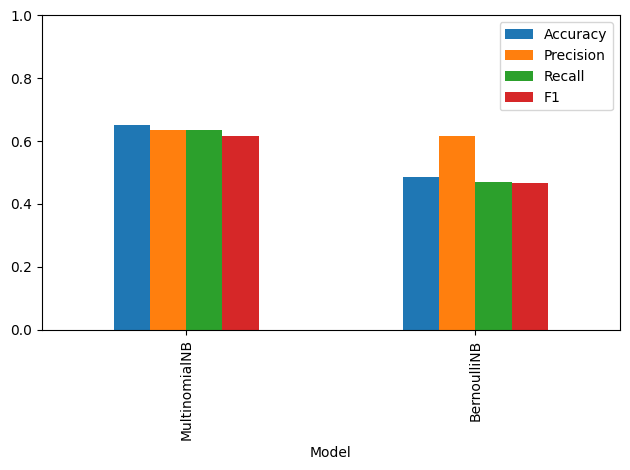

In [9]:


# ALGORITHM:
# 1. Import libraries and load the 20 Newsgroups dataset.
# 2. Remove headers, footers and quotations.
# 3. Convert text into word-count and binary features.
# 4. Train Multinomial and Bernoulli Naive Bayes models.
# 5. Predict test document classes.
# 6. Calculate Accuracy, Macro Precision, Recall and F1-Score.
# 7. Display and compare results in a table.
# 8. Plot a comparison bar chart.
# 9. Stop.
# Algorithm:
# 1. Load 20 Newsgroups data.
# 2. Convert text into word-count and binary features.
# 3. Train Multinomial and Bernoulli Naive Bayes.
# 4. Predict and calculate evaluation metrics.
# 5. Compare results using a bar chart.

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.metrics import *

tr = fetch_20newsgroups(subset='train', remove=('headers','footers','quotes'))
te = fetch_20newsgroups(subset='test', remove=('headers','footers','quotes'))

print("Train:", len(tr.data), "Test:", len(te.data))
r = []

for binary, m in [(False, MultinomialNB()), (True, BernoulliNB())]:
    v = CountVectorizer(stop_words='english', min_df=2, binary=binary)
    X = v.fit_transform(tr.data)
    Z = v.transform(te.data)
    m.fit(X, tr.target)
    p = m.predict(Z)
    r.append([m.__class__.__name__, accuracy_score(te.target,p),
              precision_score(te.target,p,average='macro',zero_division=0),
              recall_score(te.target,p,average='macro',zero_division=0),
              f1_score(te.target,p,average='macro',zero_division=0)])

r = pd.DataFrame(r, columns=['Model','Accuracy','Precision','Recall','F1'])
print(r.round(3))
r.set_index('Model').plot(kind='bar', ylim=(0,1))
plt.tight_layout()
plt.show()
